# 2024 OPM FEVS – Ayrılma Niyetini En Çok Etkileyen Sorular

**Etiket:** `y = 1` → 1 yıl içinde ayrılmayı düşünüyor, `0` → düşünmüyor.
**Özellikler:** 73 Likert sorusu. Q46, Q70 ve Q72 hariç; bu üçü genel memnuniyetin kendisini ölçer, etiketin neredeyse eş anlamlısıdır.

Soruların çoğu birbiriyle güçlü ilişkili (ör. Q86 "işim ilham veriyor" ↔ Q87 "işim başarı hissi veriyor"). Bu yüzden önem üç yöntemle ölçülür, ve bir soru ancak üçünde de üst sıralardaysa "en etkili" kabul edilir:

| Yöntem | Ne ölçer |
|---|---|
| **Korelasyon** | Tek başına ilişki (diğer soruları hesaba katmaz) |
| **LightGBM + SHAP** | Tüm sorular birlikteyken her sorunun tahmine **kendine özgü katkısı** (doğrusal olmayan etkiler dahil) |
| **Lojistik regresyon** | Standartlaştırılmış katsayı: diğer sorular sabitken 1 standart sapmalık artışın ayrılma olasılığına etkisi (odds oranı) |

> Bu bir **önem analizi**dir, nihai model değildir; hiperparametre ayarı yapılmadı. "Etki" kelimesi istatistiksel katkı anlamındadır, nedensellik değildir.

In [1]:
from pathlib import Path
from textwrap import fill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from IPython.display import display

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # notebook'lar notebooks/ klasöründen çalışır
    ROOT = ROOT.parent
DATA, FIG, TAB = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

def kaydet(ad):
    """Grafiği reports/figures klasörüne kaydeder ve gösterir."""
    plt.savefig(FIG / f"{ad}.png", dpi=110, bbox_inches="tight")
    plt.show()
df = pd.read_pickle(DATA / "fevs2024_clean.pkl")
cb = pd.read_excel(DATA / "2024" / "2024_OPM_FEVS_PRDF_Codebook.xlsx", sheet_name="Survey Items")
cb["VARIABLE"] = cb["VARIABLE"].str.strip()
text_map = cb.groupby("VARIABLE")["ITEM TEXT"].first().str.strip().to_dict()

Q16_COLS = [f"Q16_{i}" for i in range(1, 7)]
LIKERT_COLS = [c for c in df.columns if c.startswith("Q") and c not in Q16_COLS and c != "Q91"]
PROXY = ["Q46", "Q70", "Q72"]
FEATS = [q for q in LIKERT_COLS if q not in PROXY]

df = df[df["DLEAVING"].notna()]
X = df[FEATS].astype("float32")
y = (df["DLEAVING"] != "No").astype(int)
w = df["POSTWT"]
X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(X, y, w, test_size=0.2, stratify=y, random_state=42)
print(f"Eğitim: {len(X_tr):,}  Test: {len(X_te):,}  Özellik: {len(FEATS)}  Ayrılma oranı (ağırlıklı): {np.average(y, weights=w):.3f}")

Eğitim: 505,838  Test: 126,460  Özellik: 73  Ayrılma oranı (ağırlıklı): 0.368


## 1. Korelasyon (tek başına ilişki)

In [2]:
def wcorr(x, y, w):
    m = x.notna(); x, y, w = x[m], y[m], w[m]
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    return np.average((x - mx) * (y - my), weights=w) / np.sqrt(np.average((x - mx) ** 2, weights=w) * np.average((y - my) ** 2, weights=w))

corr = pd.Series({q: wcorr(X[q], y, w) for q in FEATS}, name="r")
corr.sort_values().head(10).to_frame().assign(soru=lambda d: d.index.map(text_map)).round(3)

,r,soru
Q86,-0.362,My job inspires me.
Q88,-0.361,I feel a strong personal attachment to my organization.
Q6,-0.350,My talents are used well in the workplace.
Q67,-0.339,How satisfied are you with your involvement in decisions that affect your work?
Q87,-0.336,The work I do gives me a sense of accomplishment.
Q69,-0.331,How satisfied are you with the recognition you receive for doing a good job?
Q47,-0.330,I believe the results of this survey will be used to make my agency a better place to ...
Q3,-0.328,My work gives me a feeling of personal accomplishment.
Q68,-0.326,How satisfied are you with the information you receive from management on what's going...
Q1,-0.324,I am given a real opportunity to improve my skills in my organization.


## 2. LightGBM + SHAP

In [3]:
model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63, min_child_samples=200,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
model.fit(X_tr, y_tr, sample_weight=w_tr)
p_te = model.predict_proba(X_te)[:, 1]
print(f"Test ROC-AUC (ağırlıklı): {roc_auc_score(y_te, p_te, sample_weight=w_te):.4f}")

# SHAP değerleri: LightGBM'in yerleşik TreeSHAP'i (pred_contrib) – test setinden 60 bin satır
Xs = X_te.sample(60_000, random_state=0)
contrib = model.booster_.predict(Xs, pred_contrib=True)[:, :-1]      # son kolon = baz değer
SH = pd.DataFrame(contrib, columns=FEATS, index=Xs.index)
shap_imp = SH.abs().mean().rename("ort_|SHAP|")
# Yön: soru puanı ile SHAP değeri arasındaki korelasyon (negatif = puan arttıkça ayrılma olasılığı düşüyor)
shap_dir = pd.Series({q: np.corrcoef(Xs[q].fillna(Xs[q].median()), SH[q])[0, 1] for q in FEATS}, name="yön_r")
shap_tab = pd.concat([shap_imp, shap_dir], axis=1).sort_values("ort_|SHAP|", ascending=False)
shap_tab["pay_%"] = 100 * shap_tab["ort_|SHAP|"] / shap_tab["ort_|SHAP|"].sum()
shap_tab.head(15).assign(soru=lambda d: d.index.map(text_map)).round(4)

Test ROC-AUC (ağırlıklı): 0.7740


,ort_|SHAP|,yön_r,pay_%,soru
Q88,0.2596,-0.9546,9.7907,I feel a strong personal attachment to my organization.
Q86,0.2077,-0.9720,7.8347,My job inspires me.
Q71,0.2077,-0.9414,7.8323,"Considering everything, how satisfied are you with your pay?"
Q6,0.1878,-0.9450,7.0828,My talents are used well in the workplace.
Q47,0.1025,-0.9359,3.8638,I believe the results of this survey will be used to make my agency a better place to ...
Q69,0.0701,-0.8389,2.6438,How satisfied are you with the recognition you receive for doing a good job?
Q87,0.0624,-0.9199,2.3546,The work I do gives me a sense of accomplishment.
Q1,0.0621,-0.9096,2.3417,I am given a real opportunity to improve my skills in my organization.
Q5,0.0599,-0.8225,2.2601,My workload is reasonable.
Q61,0.0550,-0.8746,2.0752,"Overall, how good a job do you feel is being done by the manager directly above your i..."


## 3. Lojistik regresyon (standartlaştırılmış katsayılar)

In [4]:
med = X_tr.median()
sc = StandardScaler().fit(X_tr.fillna(med))
lr = LogisticRegression(max_iter=2000, C=1.0)
lr.fit(sc.transform(X_tr.fillna(med)), y_tr, sample_weight=w_tr)
p_lr = lr.predict_proba(sc.transform(X_te.fillna(med)))[:, 1]
print(f"Test ROC-AUC (ağırlıklı): {roc_auc_score(y_te, p_lr, sample_weight=w_te):.4f}")
coef = pd.Series(lr.coef_[0], index=FEATS, name="katsayı")
lr_tab = coef.to_frame().assign(odds_oranı=np.exp(coef), abs=coef.abs()).sort_values("abs", ascending=False).drop(columns="abs")
lr_tab.head(15).assign(soru=lambda d: d.index.map(text_map)).round(3)

Test ROC-AUC (ağırlıklı): 0.7648


,katsayı,odds_oranı,soru
Q88,-0.287,0.750,I feel a strong personal attachment to my organization.
Q71,-0.245,0.782,"Considering everything, how satisfied are you with your pay?"
Q6,-0.208,0.812,My talents are used well in the workplace.
Q86,-0.189,0.827,My job inspires me.
Q47,-0.152,0.859,I believe the results of this survey will be used to make my agency a better place to ...
Q90,0.116,1.123,It is important to me that my work contribute to the common good.
Q25,0.105,1.111,I can influence decisions in my work unit.
Q87,-0.100,0.905,The work I do gives me a sense of accomplishment.
Q63,-0.093,0.911,Senior leaders demonstrate support for Work-Life programs.
Q1,-0.090,0.914,I am given a real opportunity to improve my skills in my organization.


## 4. Üç yöntemin karşılaştırması

In [5]:
rank = pd.DataFrame({
    "sıra_SHAP": shap_tab["ort_|SHAP|"].rank(ascending=False),
    "sıra_lojistik": lr_tab["katsayı"].abs().rank(ascending=False),
    "sıra_korelasyon": corr.abs().rank(ascending=False),
}).astype(int)
rank["ortalama_sıra"] = rank.mean(axis=1)
rank = rank.join(shap_tab[["ort_|SHAP|", "pay_%"]]).join(lr_tab["odds_oranı"]).join(corr)
rank = rank.sort_values(["sıra_SHAP"])
TOP5 = rank.index[:5].tolist()
print("En etkili 5 soru (SHAP sırasına göre):", TOP5)
rank.head(12).assign(soru=lambda d: d.index.map(text_map)).round(3)

En etkili 5 soru (SHAP sırasına göre): ['Q88', 'Q86', 'Q71', 'Q6', 'Q47']


,sıra_SHAP,sıra_lojistik,sıra_korelasyon,ortalama_sıra,ort_|SHAP|,pay_%,odds_oranı,r,soru
Q88,1,1,2,1.333,0.260,9.791,0.750,-0.361,I feel a strong personal attachment to my organization.
Q86,2,4,1,2.333,0.208,7.835,0.827,-0.362,My job inspires me.
Q71,3,2,28,11.000,0.208,7.832,0.782,-0.283,"Considering everything, how satisfied are you with your pay?"
Q6,4,3,3,3.333,0.188,7.083,0.812,-0.350,My talents are used well in the workplace.
Q47,5,5,7,5.667,0.102,3.864,0.859,-0.330,I believe the results of this survey will be used to make my agency a better place to ...
Q69,6,27,6,13.000,0.070,2.644,0.954,-0.331,How satisfied are you with the recognition you receive for doing a good job?
Q87,7,8,5,6.667,0.062,2.355,0.905,-0.336,The work I do gives me a sense of accomplishment.
Q1,8,10,10,9.333,0.062,2.342,0.914,-0.324,I am given a real opportunity to improve my skills in my organization.
Q5,9,16,49,24.667,0.060,2.260,0.929,-0.250,My workload is reasonable.
Q61,10,13,14,12.333,0.055,2.075,0.921,-0.313,"Overall, how good a job do you feel is being done by the manager directly above your i..."


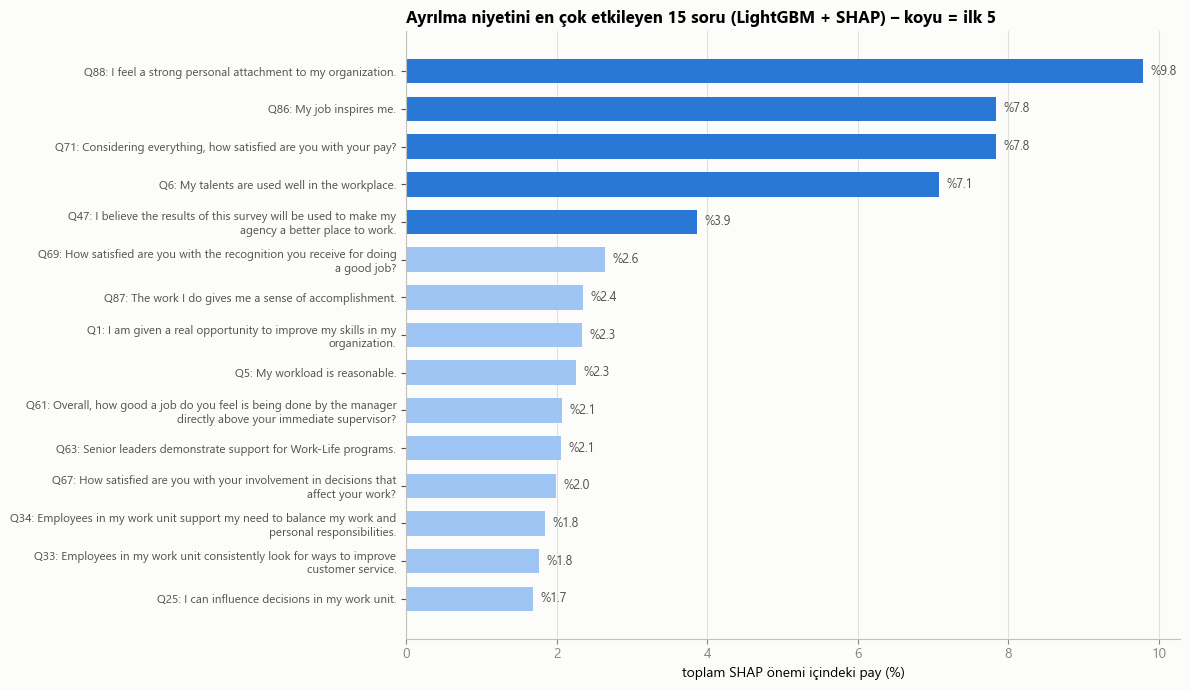

In [6]:
INK, INK2, MUTED, GRID, AXIS, SURFACE, BLUE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#2a78d6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
                     "xtick.color": MUTED, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True})
t = shap_tab.head(15)[::-1]
fig, ax = plt.subplots(figsize=(12, 7))
colors = [BLUE if q in TOP5 else "#9ec5f4" for q in t.index]
ax.barh([fill(f"{q}: {text_map[q]}", 70) for q in t.index], t["pay_%"], color=colors, height=0.65)
for yy, v in enumerate(t["pay_%"]):
    ax.text(v + 0.1, yy, f"%{v:.1f}", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("toplam SHAP önemi içindeki pay (%)")
ax.set_title("Ayrılma niyetini en çok etkileyen 15 soru (LightGBM + SHAP) – koyu = ilk 5")
plt.tight_layout(); kaydet("05_01_SHAP_ilk15")

## 5. İlk 5 soru: cevaba göre ayrılma oranı
Her çubuk: o cevabı veren çalışanların ağırlıklı ayrılma niyeti oranı.

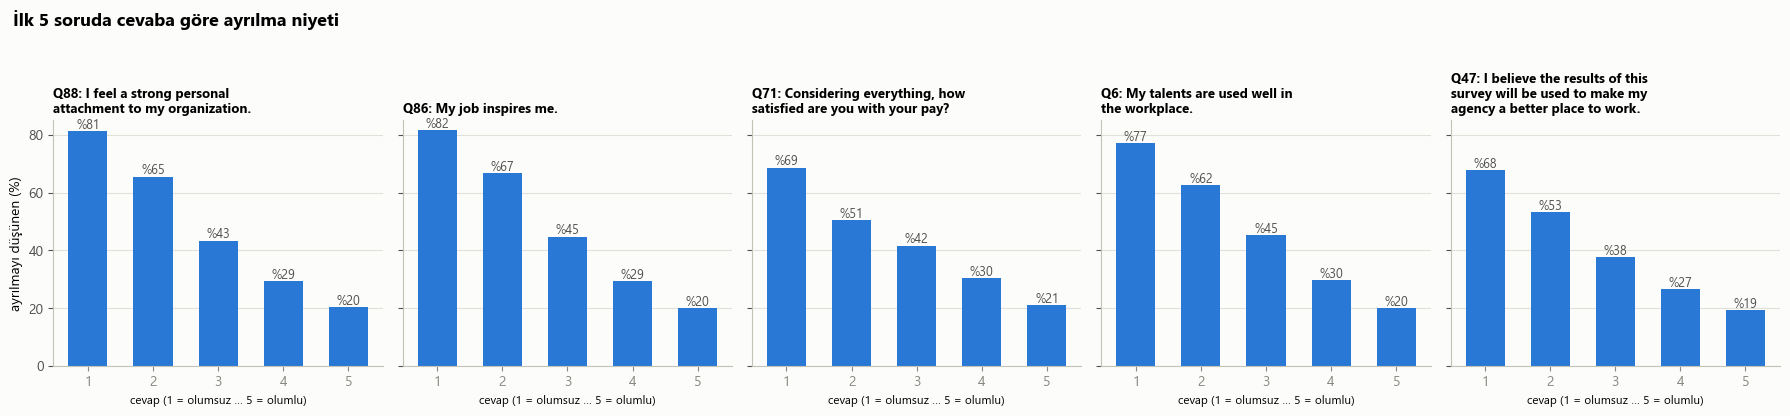

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2), sharey=True)
for ax, q in zip(axes, TOP5):
    m = X[q].notna()
    r = (y[m] * w[m]).groupby(X.loc[m, q]).sum() / w[m].groupby(X.loc[m, q]).sum() * 100
    ax.bar(r.index.astype(int), r.values, color=BLUE, width=0.6)
    for xx, v in zip(r.index.astype(int), r.values):
        ax.text(xx, v + 1, f"%{v:.0f}", ha="center", fontsize=9, color=INK2)
    ax.set_xticks([1, 2, 3, 4, 5]); ax.grid(axis="x", visible=False)
    ax.set_title(fill(f"{q}: {text_map[q]}", 34), fontsize=9.5)
    ax.set_xlabel("cevap (1 = olumsuz … 5 = olumlu)", fontsize=8.5)
axes[0].set_ylabel("ayrılmayı düşünen (%)"); axes[0].set_ylim(0, 85)
fig.suptitle("İlk 5 soruda cevaba göre ayrılma niyeti", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95]); kaydet("05_02_ilk5_soru_cevaba_gore_ayrilma")

## 6. Yorum – ayrılma niyetini en çok etkileyen 5 soru

LightGBM + SHAP ve lojistik regresyon **aynı 5 soruyu** buldu (sıralama küçük farklarla). Bu, sonucun yönteme bağlı olmadığını gösterir. Model test setinde ROC-AUC ≈ 0,77 ile çalışıyor (ayarsız, ön model).

| # | Soru | Türkçesi | Genel % pozitif | En olumsuz → en olumlu cevapta ayrılma niyeti |
|---|---|---|---|---|
| 1 | **Q88** | Kurumuma karşı güçlü bir kişisel bağlılık hissediyorum. | %62 | %81 → %20 |
| 2 | **Q86** | İşim bana ilham veriyor. | %64 | %82 → %20 |
| 3 | **Q71** | Her şey göz önüne alındığında maaşımdan ne kadar memnunsunuz? | %59 | %69 → %21 |
| 4 | **Q6** | Yeteneklerim iş yerinde iyi kullanılıyor. | %66 | %77 → %20 |
| 5 | **Q47** | Bu anketin sonuçlarının kurumumu daha iyi bir çalışma yeri yapmak için kullanılacağına inanıyorum. | %50 | %68 → %19 |

**Ne anlatıyorlar?**
1. **Q88 – Kuruma aidiyet:** Çalışanın kurumu "benim kurumum" olarak görüp görmediği. En güçlü tek belirleyici: bağlılık hissetmeyenlerin %81'i ayrılmayı düşünüyor.
2. **Q86 – İşin anlamı / ilham:** İşin kişiyi heyecanlandırması, motive etmesi. Özellikle 40 yaş altı ve kıdemi 10 yılın altında olanlarda belirleyici (04 notebook'u).
3. **Q71 – Maaş memnuniyeti:** **Tek başına korelasyonda 28. sırada**, ama model diğer sorular sabitken 3. sıraya çıkarıyor. Yani maaş, diğer sorulardan bağımsız, **kendine özgü** bir ayrılma nedeni: işini seven, kurumuna bağlı biri bile maaştan memnun değilse ayrılmayı düşünebiliyor. Korelasyonun tek başına yanıltıcı olabileceğinin iyi bir örneği.
4. **Q6 – Yeteneklerin kullanılması:** Çalışan potansiyelinin boşa harcandığını hissederse ayrılmayı düşünüyor.
5. **Q47 – Ankete / yönetime güven:** "Söylediklerim bir şeyi değiştirecek mi?" sorusu. Genel olarak en düşük puanlı sorulardan biri (%50). Askeri kurumlarda en zayıf alan (04 notebook'u). Aslında **yönetimin çalışanı dinlediğine olan inancı** ölçüyor.

**Genel tablo:** İlk 5 sorudan 4'ü (Q88, Q86, Q6, Q47) **duygusal / psikolojik** bağla ilgili, yalnızca biri (Q71) **maddi**. Ayrılma niyetini en çok açıklayan şey çalışanın işinde anlam bulması, kurumuna ait hissetmesi ve sesinin duyulduğuna inanması; bunun yanında maaş ayrı ve bağımsız bir etken.

**Dikkat:**
- Q90 ("işimin kamu yararına katkısı benim için önemli") ve Q25 ("birimimdeki kararları etkileyebiliyorum") lojistik regresyonda **pozitif** katsayı aldı: diğer sorular sabitken, bu konularda yüksek puan verenler biraz *daha fazla* ayrılmayı düşünüyor. Olası açıklama: misyonuna çok bağlı, etkili çalışanlar başka (federal) kurumlarda da fırsat buluyor. Ancak bu çoklu doğrusallık kaynaklı bir işaret dönüşümü de olabilir; yorumlarken temkinli olunmalı.
- Bu bir **ilişki** analizidir. "Maaşı artırırsak ayrılma azalır" demek için nedensel yöntemler gerekir.


In [8]:
OUT = TAB / "FEVS2024_etkili_sorular.xlsx"
with pd.ExcelWriter(OUT) as xw:
    rank.assign(soru=lambda d: d.index.map(text_map)).to_excel(xw, sheet_name="Karsilastirma")
    shap_tab.assign(soru=lambda d: d.index.map(text_map)).to_excel(xw, sheet_name="SHAP")
    lr_tab.assign(soru=lambda d: d.index.map(text_map)).to_excel(xw, sheet_name="Lojistik")
    corr.to_frame().assign(soru=lambda d: d.index.map(text_map)).to_excel(xw, sheet_name="Korelasyon")
print("Kaydedildi:", OUT)

Kaydedildi: ~\fevs_proje\reports\tables\FEVS2024_etkili_sorular.xlsx
